In [25]:
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
import random
import time
import copy
import matplotlib.pyplot as plt

In [26]:
# --- Reproduksibilitas ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# --- Konfigurasi Perangkat ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan perangkat: {device}")

Menggunakan perangkat: cpu


In [27]:
# --- Download Dataset Asli ---
import os
# Membuat direktori jika belum ada
os.makedirs('./data', exist_ok=True)

print("Mengunduh dataset Oxford-IIIT Pet (proses ini mungkin memakan waktu beberapa menit)...")
full_dataset = datasets.OxfordIIITPet(root='./data', split='trainval', target_types='category', download=True)
print(f"Total citra terunduh: {len(full_dataset)}")

# --- Pengecekan dan Pemilihan Kelas Secara Aman ---
class_names = full_dataset.classes

# Target yang diperbarui dengan menggunakan spasi sesuai dengan format dataset
target_cats = ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair']
target_dogs = ['American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Boxer']
all_targets = target_cats + target_dogs

selected_class_names = []
selected_class_indices = []

print("\n=== Proses Pemilihan Kelas ===")
for target in all_targets:
    found = False
    for idx, name in enumerate(class_names):
        # Membandingkan dengan string persis
        if target == name:
            selected_class_names.append(name)
            selected_class_indices.append(idx)
            found = True
            print(f"[OK] Menemukan kelas -> '{name}' (Index Asli: {idx})")
            break

    if not found:
         print(f"[ERROR] Tidak dapat menemukan kelas dengan ejaan: '{target}'")

# Verifikasi apakah kita berhasil mendapatkan tepat 10 kelas
if len(selected_class_indices) != 10:
    raise ValueError(f"Error: Diharapkan 10 kelas, tetapi hanya menemukan {len(selected_class_indices)} kelas.")

# Membuat mapping index baru (0-9) untuk 10 kelas terpilih
# Contoh: Index asli 'Abyssinian' adalah 0, dipetakan ke 0.
# Index asli 'British Shorthair' adalah 9, dipetakan ke 4, dsb.
class_mapping = {old_idx: new_idx for new_idx, old_idx in enumerate(selected_class_indices)}

# --- Filter Dataset (Menyimpan hanya 10 kelas) ---
filtered_indices = []
filtered_targets = []

for idx, (img, label) in enumerate(full_dataset):
    if label in selected_class_indices:
        filtered_indices.append(idx)
        # Simpan target dengan index baru (0-9)
        filtered_targets.append(class_mapping[label])

# Membuat Subset Dataset yang sudah difilter
filtered_dataset = Subset(full_dataset, filtered_indices)

print(f"\n=== Ringkasan Filter ===")
print(f"Total citra setelah difilter (10 kelas): {len(filtered_dataset)}")
print(f"Kelas akhir yang digunakan (Mapping Index 0-9):\n{selected_class_names}")

Mengunduh dataset Oxford-IIIT Pet (proses ini mungkin memakan waktu beberapa menit)...
Total citra terunduh: 3680

=== Proses Pemilihan Kelas ===
[OK] Menemukan kelas -> 'Abyssinian' (Index Asli: 0)
[OK] Menemukan kelas -> 'Bengal' (Index Asli: 5)
[OK] Menemukan kelas -> 'Birman' (Index Asli: 6)
[OK] Menemukan kelas -> 'Bombay' (Index Asli: 7)
[OK] Menemukan kelas -> 'British Shorthair' (Index Asli: 9)
[OK] Menemukan kelas -> 'American Bulldog' (Index Asli: 1)
[OK] Menemukan kelas -> 'American Pit Bull Terrier' (Index Asli: 2)
[OK] Menemukan kelas -> 'Basset Hound' (Index Asli: 3)
[OK] Menemukan kelas -> 'Beagle' (Index Asli: 4)
[OK] Menemukan kelas -> 'Boxer' (Index Asli: 8)

=== Ringkasan Filter ===
Total citra setelah difilter (10 kelas): 996
Kelas akhir yang digunakan (Mapping Index 0-9):
['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Boxer']


In [28]:
# --- Stratified Split ---
# 1. Pisahkan Test set (15%)
train_val_indices, test_indices, train_val_targets, test_targets = train_test_split(
    filtered_indices, filtered_targets, test_size=0.15, stratify=filtered_targets, random_state=SEED
)

# 2. Pisahkan sisa data menjadi Train (70/85) dan Validation (15/85) dari total data awal.
# Karena test_size 0.15 berarti train_val adalah 0.85 dari total.
# Proporsi val terhadap train_val adalah 0.15 / 0.85 = 0.17647...
val_ratio = 0.15 / (0.70 + 0.15)

train_indices, val_indices, train_targets, val_targets = train_test_split(
    train_val_indices, train_val_targets, test_size=val_ratio, stratify=train_val_targets, random_state=SEED
)

print(f"Jumlah Data Latih (Train): {len(train_indices)} ({(len(train_indices)/len(filtered_indices))*100:.1f}%)")
print(f"Jumlah Data Validasi (Val): {len(val_indices)} ({(len(val_indices)/len(filtered_indices))*100:.1f}%)")
print(f"Jumlah Data Uji (Test): {len(test_indices)} ({(len(test_indices)/len(filtered_indices))*100:.1f}%)")

Jumlah Data Latih (Train): 696 (69.9%)
Jumlah Data Validasi (Val): 150 (15.1%)
Jumlah Data Uji (Test): 150 (15.1%)


In [29]:
# Ekstraksi mean dan std dari weights pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
mean = weights.transforms().mean
std = weights.transforms().std

train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

train_transforms_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class CustomPetDataset(torch.utils.data.Dataset):
    def __init__(self, subset_indices, targets, original_dataset, transform=None):
        self.subset_indices = subset_indices
        self.targets = targets
        self.original_dataset = original_dataset
        self.transform = transform

    def __len__(self):
        return len(self.subset_indices)

    def __getitem__(self, idx):
        original_idx = self.subset_indices[idx]
        img, _ = self.original_dataset[original_idx]
        label = self.targets[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

def get_dataloaders(train_transform_type='aug', batch_size=32):
    train_transform = train_transforms_aug if train_transform_type == 'aug' else train_transforms_no_aug

    train_ds = CustomPetDataset(train_indices, train_targets, full_dataset, transform=train_transform)
    val_ds = CustomPetDataset(val_indices, val_targets, full_dataset, transform=eval_transforms)
    test_ds = CustomPetDataset(test_indices, test_targets, full_dataset, transform=eval_transforms)

    # PERUBAHAN PENTING: num_workers diubah menjadi 0 untuk mencegah hang di Colab
    dataloaders = {
        'train': DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0),
        'val': DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0),
        'test': DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=0)
    }
    return dataloaders

dataloaders = get_dataloaders('aug')
print("DataLoaders siap.")

DataLoaders siap.


In [30]:
def train_model(model, dataloaders, criterion, optimizer, num_epochs=25, patience=4, device=device):
    since = time.time()
    val_acc_history = []
    train_loss_history = []
    val_loss_history = []

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    epochs_no_improve = 0
    converged_epoch = 0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0
            all_preds = []
            all_labels = []

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    _, preds = torch.max(outputs, 1)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

                if phase == 'val':
                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(labels.cpu().numpy())

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'train':
                train_loss_history.append(epoch_loss)
            elif phase == 'val':
                val_loss_history.append(epoch_loss)
                val_acc_history.append(epoch_acc.item())

                # Deep copy model & Early Stopping Logic
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                    converged_epoch = epoch + 1
                else:
                    epochs_no_improve += 1

        print()
        if epochs_no_improve >= patience:
            print(f'Early stopping diaktifkan pada epoch {epoch+1}')
            break

    time_elapsed = time.time() - since
    print(f'Pelatihan selesai dalam {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f} (Epoch {converged_epoch})')

    # Load best model weights
    model.load_state_dict(best_model_wts)

    return model, {
        'train_loss': train_loss_history,
        'val_loss': val_loss_history,
        'val_acc': val_acc_history,
        'converged_epoch': converged_epoch,
        'time_elapsed': time_elapsed
    }

def evaluate_model(model, dataloaders, device=device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    return acc, macro_f1, all_preds, all_labels

In [31]:
import gc
# Membersihkan sisa memori GPU sebelum memulai tugas berat
torch.cuda.empty_cache()
gc.collect()

print("=== Kondisi B1: Baseline from Scratch ===")
# 1. Inisialisasi Model TANPA weights pretrained
model_b1 = models.resnet18(weights=None)
num_features = model_b1.fc.in_features
model_b1.fc = nn.Linear(num_features, 10)
model_b1 = model_b1.to(device)

# 2. Verifikasi Parameter
trainable_params_b1 = sum(p.numel() for p in model_b1.parameters() if p.requires_grad)
print(f"B1 Trainable Parameters: {trainable_params_b1:,}")

# 3. Konfigurasi Training
criterion = nn.CrossEntropyLoss()
optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)

# 4. Eksekusi Training (DIPERINGAN: Max 10 epoch, patience 3)
print("\nMemulai training B1...")
model_b1, history_b1 = train_model(
    model_b1,
    dataloaders,
    criterion,
    optimizer_b1,
    num_epochs=10,  # <-- Diubah dari 20 menjadi 10
    patience=3      # <-- Menggunakan batas minimum kesabaran early stopping
)

# 5. Evaluasi pada Test Set
test_acc_b1, test_f1_b1, _, _ = evaluate_model(model_b1, dataloaders)
print(f"\nB1 Test Accuracy: {test_acc_b1:.4f} | Test Macro F1: {test_f1_b1:.4f}")

=== Kondisi B1: Baseline from Scratch ===
B1 Trainable Parameters: 11,181,642

Memulai training B1...
Epoch 1/10
----------
Train Loss: 2.4319 Acc: 0.1782
Val Loss: 17.5077 Acc: 0.1133

Epoch 2/10
----------
Train Loss: 2.1536 Acc: 0.2299
Val Loss: 2.2305 Acc: 0.1933

Epoch 3/10
----------
Train Loss: 2.0613 Acc: 0.2486
Val Loss: 2.3926 Acc: 0.2067

Epoch 4/10
----------
Train Loss: 1.9755 Acc: 0.2888
Val Loss: 2.0561 Acc: 0.2600

Epoch 5/10
----------
Train Loss: 1.8885 Acc: 0.3218
Val Loss: 2.5258 Acc: 0.2200

Epoch 6/10
----------
Train Loss: 1.9272 Acc: 0.3075
Val Loss: 2.1989 Acc: 0.2600

Epoch 7/10
----------
Train Loss: 1.8273 Acc: 0.3420
Val Loss: 2.2399 Acc: 0.2800

Epoch 8/10
----------
Train Loss: 1.7408 Acc: 0.3693
Val Loss: 2.1788 Acc: 0.3133

Epoch 9/10
----------
Train Loss: 1.7117 Acc: 0.4023
Val Loss: 1.8900 Acc: 0.3400

Epoch 10/10
----------
Train Loss: 1.6143 Acc: 0.4339
Val Loss: 1.7951 Acc: 0.3600

Pelatihan selesai dalam 37m 10s
Best val Acc: 0.360000 (Epoch 10)


In [32]:
print("\n=== Kondisi B2: Feature Extraction ===")
# 1. Inisialisasi Model DENGAN weights pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

# 2. Bekukan Backbone
for param in model_b2.parameters():
    param.requires_grad = False

# 3. Ganti Classifier (otomatis requires_grad=True)
num_features = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_features, 10)
model_b2 = model_b2.to(device)

# 4. Verifikasi Parameter (Pastikan jauh lebih sedikit dari B1)
trainable_params_b2 = sum(p.numel() for p in model_b2.parameters() if p.requires_grad)
print(f"B2 Trainable Parameters: {trainable_params_b2:,}") # Seharusnya sekitar 5,130

# 5. Konfigurasi Training (Hanya optimasi classifier)
criterion = nn.CrossEntropyLoss()
optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

# 6. Eksekusi Training
model_b2, history_b2 = train_model(model_b2, dataloaders, criterion, optimizer_b2, num_epochs=20, patience=4)

# 7. Evaluasi
test_acc_b2, test_f1_b2, _, _ = evaluate_model(model_b2, dataloaders)
print(f"B2 Test Accuracy: {test_acc_b2:.4f} | Test Macro F1: {test_f1_b2:.4f}")


=== Kondisi B2: Feature Extraction ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 82.2MB/s]


B2 Trainable Parameters: 5,130
Epoch 1/20
----------
Train Loss: 1.9891 Acc: 0.3161
Val Loss: 1.3424 Acc: 0.6667

Epoch 2/20
----------
Train Loss: 1.1692 Acc: 0.7371
Val Loss: 0.8259 Acc: 0.8867

Epoch 3/20
----------
Train Loss: 0.7953 Acc: 0.8635
Val Loss: 0.5913 Acc: 0.8933

Epoch 4/20
----------
Train Loss: 0.6213 Acc: 0.8879
Val Loss: 0.4942 Acc: 0.9000

Epoch 5/20
----------
Train Loss: 0.5252 Acc: 0.8922
Val Loss: 0.4259 Acc: 0.9133

Epoch 6/20
----------
Train Loss: 0.4596 Acc: 0.9037
Val Loss: 0.3898 Acc: 0.9267

Epoch 7/20
----------
Train Loss: 0.4308 Acc: 0.9167
Val Loss: 0.3372 Acc: 0.9400

Epoch 8/20
----------
Train Loss: 0.3922 Acc: 0.9066
Val Loss: 0.3240 Acc: 0.9133

Epoch 9/20
----------
Train Loss: 0.3395 Acc: 0.9267
Val Loss: 0.2924 Acc: 0.9267

Epoch 10/20
----------
Train Loss: 0.3285 Acc: 0.9239
Val Loss: 0.2859 Acc: 0.9333

Epoch 11/20
----------
Train Loss: 0.2965 Acc: 0.9382
Val Loss: 0.2776 Acc: 0.9200

Early stopping diaktifkan pada epoch 11
Pelatihan sele

In [33]:
print("\n=== Kondisi B3: Progressive Fine-Tuning ===")
# 1. Inisialisasi Ulang dengan weights pretrained
model_b3 = models.resnet18(weights=weights)

# 2. Bekukan Semua Dulu
for param in model_b3.parameters():
    param.requires_grad = False

# 3. Ganti Classifier
num_features = model_b3.fc.in_features
model_b3.fc = nn.Linear(num_features, 10)

# 4. Unfreeze layer4
for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3 = model_b3.to(device)

# 5. Verifikasi Parameter
trainable_params_b3 = sum(p.numel() for p in model_b3.parameters() if p.requires_grad)
print(f"B3 Trainable Parameters: {trainable_params_b3:,}")

# 6. Optimasi Differential Learning Rate
criterion = nn.CrossEntropyLoss()
optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

# 7. Eksekusi Training
model_b3, history_b3 = train_model(model_b3, dataloaders, criterion, optimizer_b3, num_epochs=20, patience=4)

# 8. Evaluasi
test_acc_b3, test_f1_b3, _, _ = evaluate_model(model_b3, dataloaders)
print(f"B3 Test Accuracy: {test_acc_b3:.4f} | Test Macro F1: {test_f1_b3:.4f}")


=== Kondisi B3: Progressive Fine-Tuning ===
B3 Trainable Parameters: 8,398,858
Epoch 1/20
----------
Train Loss: 1.1970 Acc: 0.6365
Val Loss: 0.3371 Acc: 0.9000

Epoch 2/20
----------
Train Loss: 0.3223 Acc: 0.9253
Val Loss: 0.2153 Acc: 0.9267

Epoch 3/20
----------
Train Loss: 0.1813 Acc: 0.9569
Val Loss: 0.2207 Acc: 0.9267

Epoch 4/20
----------
Train Loss: 0.1021 Acc: 0.9828
Val Loss: 0.1808 Acc: 0.9467

Epoch 5/20
----------
Train Loss: 0.0794 Acc: 0.9871
Val Loss: 0.1863 Acc: 0.9333

Epoch 6/20
----------
Train Loss: 0.0630 Acc: 0.9885
Val Loss: 0.1876 Acc: 0.9600

Epoch 7/20
----------
Train Loss: 0.0328 Acc: 0.9957
Val Loss: 0.1871 Acc: 0.9533

Epoch 8/20
----------
Train Loss: 0.0251 Acc: 0.9986
Val Loss: 0.1974 Acc: 0.9533

Epoch 9/20
----------
Train Loss: 0.0182 Acc: 0.9986
Val Loss: 0.1862 Acc: 0.9400

Epoch 10/20
----------
Train Loss: 0.0158 Acc: 1.0000
Val Loss: 0.1659 Acc: 0.9533

Early stopping diaktifkan pada epoch 10
Pelatihan selesai dalam 20m 35s
Best val Acc: 0.9

In [34]:
print("\n=== Kondisi B4: Tanpa Data Augmentation (Memakai konfigurasi B3) ===")
# 1. Siapkan Dataloader khusus tanpa augmentasi
dataloaders_no_aug = get_dataloaders(train_transform_type='no_aug')

# 2. Setup Model persis seperti B3
model_b4 = models.resnet18(weights=weights)
for param in model_b4.parameters(): param.requires_grad = False
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
for param in model_b4.layer4.parameters(): param.requires_grad = True
model_b4 = model_b4.to(device)

# 3. Optimasi dan Loss
optimizer_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

# 4. Eksekusi Training pada Dataloader TANPA Augmentasi
model_b4, history_b4 = train_model(model_b4, dataloaders_no_aug, criterion, optimizer_b4, num_epochs=20, patience=4)

# 5. Evaluasi
test_acc_b4, test_f1_b4, _, _ = evaluate_model(model_b4, dataloaders_no_aug)
print(f"B4 Test Accuracy (No Aug): {test_acc_b4:.4f} | Test Macro F1: {test_f1_b4:.4f}")


=== Kondisi B4: Tanpa Data Augmentation (Memakai konfigurasi B3) ===
Epoch 1/20
----------
Train Loss: 1.0979 Acc: 0.6652
Val Loss: 0.3602 Acc: 0.9000

Epoch 2/20
----------
Train Loss: 0.1847 Acc: 0.9727
Val Loss: 0.2360 Acc: 0.9400

Epoch 3/20
----------
Train Loss: 0.0758 Acc: 0.9899
Val Loss: 0.2453 Acc: 0.9067

Epoch 4/20
----------
Train Loss: 0.0274 Acc: 0.9986
Val Loss: 0.2161 Acc: 0.9267

Epoch 5/20
----------
Train Loss: 0.0152 Acc: 1.0000
Val Loss: 0.2030 Acc: 0.9400

Epoch 6/20
----------
Train Loss: 0.0091 Acc: 1.0000
Val Loss: 0.1924 Acc: 0.9400

Early stopping diaktifkan pada epoch 6
Pelatihan selesai dalam 11m 58s
Best val Acc: 0.940000 (Epoch 2)
B4 Test Accuracy (No Aug): 0.9267 | Test Macro F1: 0.9266


In [35]:
print("\n=== Kondisi B5: Arsitektur Pembanding (EfficientNet-B0) ===")
# 1. Inisialisasi Model EfficientNet
weights_b5 = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = models.efficientnet_b0(weights=weights_b5)

# 2. Bekukan Semua Dulu
for param in model_b5.parameters():
    param.requires_grad = False

# 3. Ganti Classifier (Pada EfficientNet, classifier ada di `model.classifier`)
# Classifier EfficientNet B0 biasanya terdiri dari Dropout lalu Linear layer
num_features_b5 = model_b5.classifier[1].in_features
model_b5.classifier[1] = nn.Linear(num_features_b5, 10)

# 4. Unfreeze blok terakhir (Di EfficientNet, blok terakhir adalah `features[-1]` atau `features[-2]`)
# Kita unfreeze layer features terakhir sebelum classifier
for param in model_b5.features[-2:].parameters():
    param.requires_grad = True

model_b5 = model_b5.to(device)
trainable_params_b5 = sum(p.numel() for p in model_b5.parameters() if p.requires_grad)
print(f"B5 Trainable Parameters: {trainable_params_b5:,}")

# 5. Optimasi
optimizer_b5 = torch.optim.AdamW([
    {"params": model_b5.features[-2:].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

# 6. Eksekusi Training (Kembali gunakan dataloaders dengan augmentasi)
model_b5, history_b5 = train_model(model_b5, dataloaders, criterion, optimizer_b5, num_epochs=20, patience=4)

# 7. Evaluasi
test_acc_b5, test_f1_b5, preds_b5, labels_b5 = evaluate_model(model_b5, dataloaders) # Simpan preds utk failure analysis
print(f"B5 Test Accuracy: {test_acc_b5:.4f} | Test Macro F1: {test_f1_b5:.4f}")


=== Kondisi B5: Arsitektur Pembanding (EfficientNet-B0) ===
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 103MB/s]


B5 Trainable Parameters: 1,142,202
Epoch 1/20
----------
Train Loss: 1.7568 Acc: 0.5402
Val Loss: 0.9176 Acc: 0.8933

Epoch 2/20
----------
Train Loss: 0.8455 Acc: 0.8506
Val Loss: 0.4647 Acc: 0.9133

Epoch 3/20
----------
Train Loss: 0.4852 Acc: 0.9066
Val Loss: 0.3294 Acc: 0.9333

Epoch 4/20
----------
Train Loss: 0.3540 Acc: 0.9310
Val Loss: 0.2628 Acc: 0.9267

Epoch 5/20
----------
Train Loss: 0.2848 Acc: 0.9382
Val Loss: 0.2318 Acc: 0.9333

Epoch 6/20
----------
Train Loss: 0.2480 Acc: 0.9382
Val Loss: 0.2317 Acc: 0.9133

Epoch 7/20
----------
Train Loss: 0.1933 Acc: 0.9454
Val Loss: 0.2158 Acc: 0.9267

Early stopping diaktifkan pada epoch 7
Pelatihan selesai dalam 9m 49s
Best val Acc: 0.933333 (Epoch 3)
B5 Test Accuracy: 0.9067 | Test Macro F1: 0.9060


Berhasil menyimpan log evaluasi ke 'metrics_log.json'


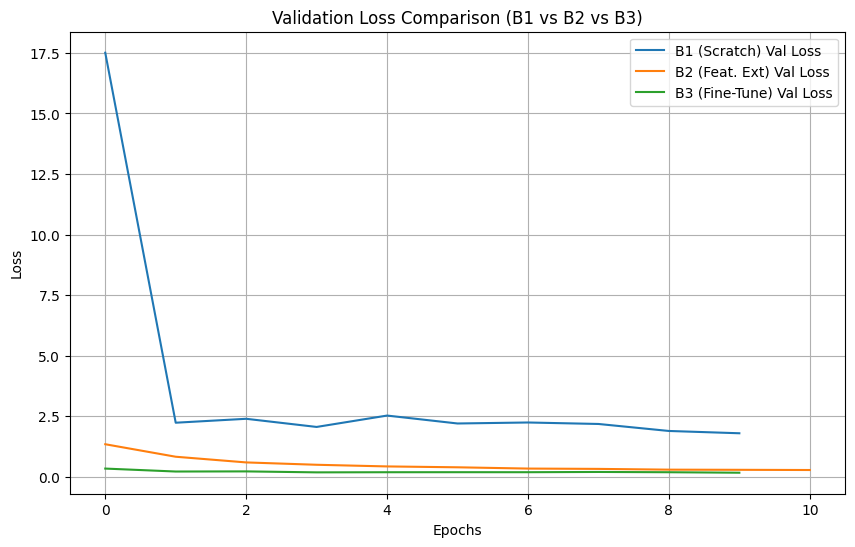

In [36]:
import json

results_log = {
    "B1_Scratch": {
        "trainable_params": trainable_params_b1,
        "epochs": history_b1['converged_epoch'],
        "time_s": history_b1['time_elapsed'],
        "test_acc": test_acc_b1,
        "test_macro_f1": test_f1_b1
    },
    "B2_FeatureExtraction": {
        "trainable_params": trainable_params_b2,
        "epochs": history_b2['converged_epoch'],
        "time_s": history_b2['time_elapsed'],
        "test_acc": test_acc_b2,
        "test_macro_f1": test_f1_b2
    },
    "B3_FineTuning": {
        "trainable_params": trainable_params_b3,
        "epochs": history_b3['converged_epoch'],
        "time_s": history_b3['time_elapsed'],
        "test_acc": test_acc_b3,
        "test_macro_f1": test_f1_b3
    },
    "B4_NoAugmentation": {
        "trainable_params": trainable_params_b3, # Sama dengan B3
        "epochs": history_b4['converged_epoch'],
        "time_s": history_b4['time_elapsed'],
        "test_acc": test_acc_b4,
        "test_macro_f1": test_f1_b4
    },
     "B5_EfficientNet": {
        "trainable_params": trainable_params_b5,
        "epochs": history_b5['converged_epoch'],
        "time_s": history_b5['time_elapsed'],
        "test_acc": test_acc_b5,
        "test_macro_f1": test_f1_b5
    }
}

with open('metrics_log.json', 'w') as f:
    json.dump(results_log, f, indent=4)

print("Berhasil menyimpan log evaluasi ke 'metrics_log.json'")

# --- Contoh Visualisasi Loss (Untuk C1) ---
plt.figure(figsize=(10,6))
plt.plot(history_b1['val_loss'], label='B1 (Scratch) Val Loss')
plt.plot(history_b2['val_loss'], label='B2 (Feat. Ext) Val Loss')
plt.plot(history_b3['val_loss'], label='B3 (Fine-Tune) Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Validation Loss Comparison (B1 vs B2 vs B3)')
plt.legend()
plt.grid(True)
plt.savefig('loss_comparison.png')
plt.show()

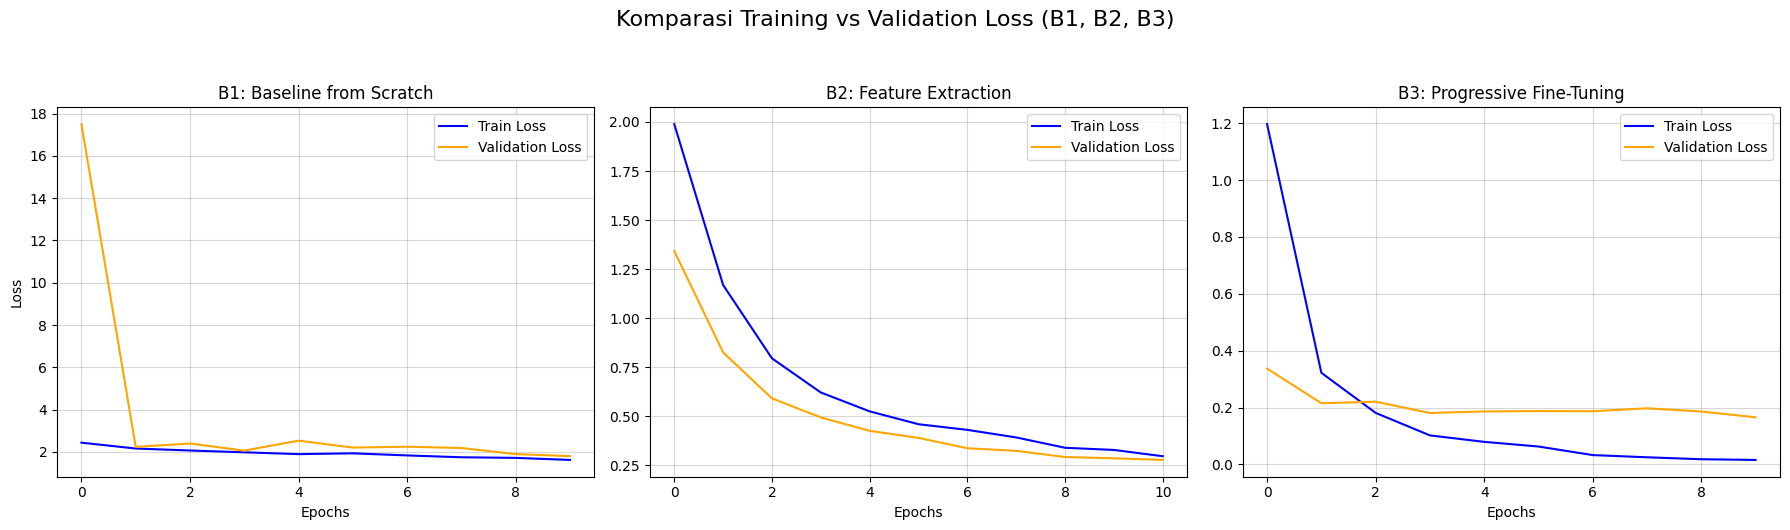

In [37]:
import matplotlib.pyplot as plt

# Membuat figure dengan 3 subplot berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Grafik B1 (Scratch) ---
axes[0].plot(history_b1['train_loss'], label='Train Loss', color='blue')
axes[0].plot(history_b1['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title('B1: Baseline from Scratch', fontsize=12)
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.5)

# --- Grafik B2 (Feature Extraction) ---
axes[1].plot(history_b2['train_loss'], label='Train Loss', color='blue')
axes[1].plot(history_b2['val_loss'], label='Validation Loss', color='orange')
axes[1].set_title('B2: Feature Extraction', fontsize=12)
axes[1].set_xlabel('Epochs')
axes[1].legend()
axes[1].grid(True, alpha=0.5)

# --- Grafik B3 (Progressive Fine-Tuning) ---
axes[2].plot(history_b3['train_loss'], label='Train Loss', color='blue')
axes[2].plot(history_b3['val_loss'], label='Validation Loss', color='orange')
axes[2].set_title('B3: Progressive Fine-Tuning', fontsize=12)
axes[2].set_xlabel('Epochs')
axes[2].legend()
axes[2].grid(True, alpha=0.5)

# Menambahkan judul utama dan merapikan layout
plt.suptitle('Komparasi Training vs Validation Loss (B1, B2, B3)', fontsize=16, y=1.05)
plt.tight_layout()

# Menyimpan gambar agar bisa didownload dan dimasukkan ke PDF laporan
plt.savefig('grafik_loss_lengkap.png', bbox_inches='tight', dpi=300)
plt.show()

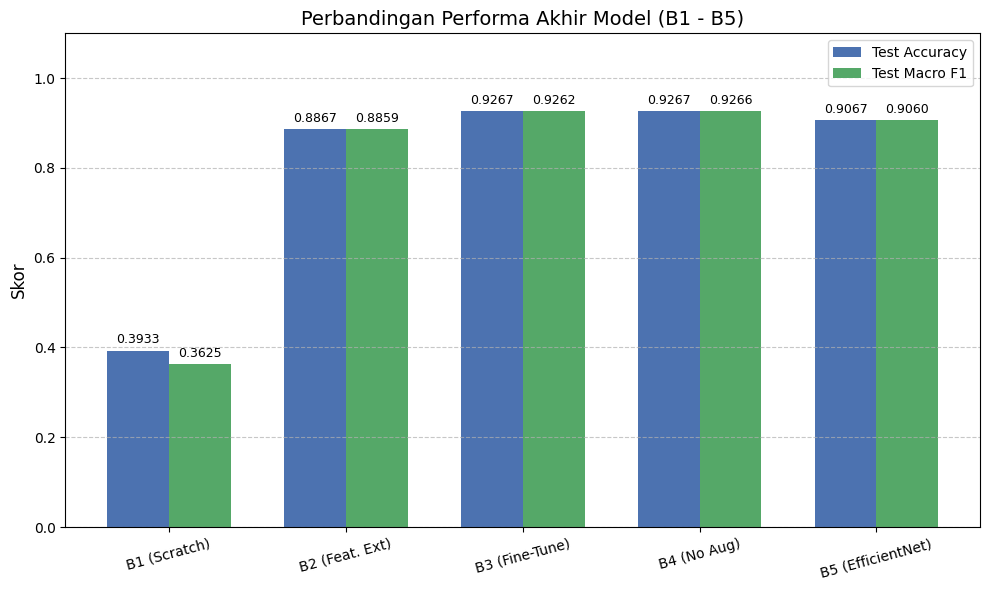

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Label untuk sumbu X
labels = ['B1 (Scratch)', 'B2 (Feat. Ext)', 'B3 (Fine-Tune)', 'B4 (No Aug)', 'B5 (EfficientNet)']

# Data berdasarkan hasil riil Anda
test_accs = [0.3933, 0.8867, 0.9267, 0.9267, 0.9067]
test_f1s = [0.3625, 0.8859, 0.9262, 0.9266, 0.9060]

x = np.arange(len(labels))  # lokasi label
width = 0.35  # lebar batang

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, test_accs, width, label='Test Accuracy', color='#4C72B0')
rects2 = ax.bar(x + width/2, test_f1s, width, label='Test Macro F1', color='#55A868')

# Menambahkan teks, judul, dan label
ax.set_ylabel('Skor', fontsize=12)
ax.set_title('Perbandingan Performa Akhir Model (B1 - B5)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15)
ax.legend()
ax.set_ylim(0, 1.1) # Set limit Y sedikit lebih tinggi agar teks nilai muat
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Fungsi untuk menambahkan angka di atas batang
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 poin vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('bar_chart_performa.png', dpi=300)
plt.show()


--- Menguji dari Upload File Lokal ---


Saving 8b3ab28a141f0c8e8b58fcb3ae0d5d63.jpg to 8b3ab28a141f0c8e8b58fcb3ae0d5d63.jpg


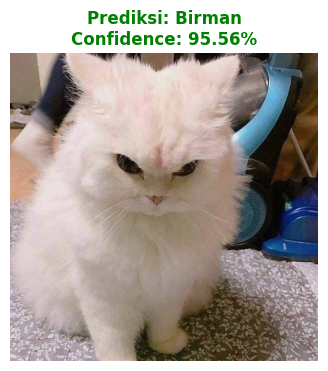


Top 3 Kemungkinan:
1. Birman (95.56%)
2. Abyssinian (1.28%)
3. Bengal (1.08%)


In [40]:
import torch
import torch.nn.functional as F
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
from google.colab import files # Jika ingin upload dari komputer

# Pastikan perangkat sudah diatur (menggunakan GPU jika ada)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. Definisi Transformasi Input ---
# Gambar baru harus diproses dengan cara yang SAMA PERSIS dengan
# data evaluasi/validasi kita saat training (Crop tengah, ToTensor, Normalize)
weights = models.ResNet18_Weights.IMAGENET1K_V1
mean = weights.transforms().mean
std = weights.transforms().std

infer_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

# --- 2. Fungsi Prediksi ---
def predict_image(model, image_path_or_url, class_names, device):
    """
    Fungsi untuk memprediksi kelas dari sebuah gambar.
    Menerima URL gambar internet atau path file lokal.
    """
    model.eval() # PENTING: Set model ke mode evaluasi

    # Memuat Gambar
    try:
        if image_path_or_url.startswith('http'):
            # Jika URL dari internet
            response = requests.get(image_path_or_url)
            img = Image.open(BytesIO(response.content)).convert('RGB')
        else:
            # Jika file lokal (dari komputer yang diupload ke Colab)
            img = Image.open(image_path_or_url).convert('RGB')
    except Exception as e:
        print(f"Error memuat gambar: {e}")
        return

    # Menerapkan transformasi
    input_tensor = infer_transform(img)
    input_batch = input_tensor.unsqueeze(0) # Menambah dimensi batch (B, C, H, W)
    input_batch = input_batch.to(device)

    # Melakukan Prediksi
    with torch.no_grad():
        output = model(input_batch)

        # Menghitung probabilitas dengan Softmax
        probabilities = F.softmax(output, dim=1)

        # Mendapatkan confidence tertinggi dan kelasnya
        confidence, predicted_idx = torch.max(probabilities, 1)

        predicted_class_name = class_names[predicted_idx.item()]
        confidence_percent = confidence.item() * 100

    # Menampilkan Hasil Visual
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"Prediksi: {predicted_class_name}\nConfidence: {confidence_percent:.2f}%",
              fontsize=12, fontweight='bold', color='green' if confidence_percent > 70 else 'orange')
    plt.axis('off')
    plt.show()

    # Menampilkan top 3 prediksi (opsional tapi informatif)
    top3_prob, top3_idx = torch.topk(probabilities, 3)
    print("\nTop 3 Kemungkinan:")
    for i in range(3):
        idx = top3_idx[0][i].item()
        prob = top3_prob[0][i].item() * 100
        print(f"{i+1}. {class_names[idx]} ({prob:.2f}%)")


# --- 3. Cara Penggunaan ---
# GANTI 'model_b3' DENGAN MODEL TERBAIK ANDA JIKA BERBEDA (misal: model_b5)
model_to_use = model_b3
# Pastikan daftar kelas menggunakan yang sama saat training (10 kelas)
classes_to_predict = selected_class_names

# Prediksi dari Upload File Lokal (Jalankan baris ini jika ingin upload gambar dari laptop/HP)
print("\n--- Menguji dari Upload File Lokal ---")
uploaded = files.upload()
for fn in uploaded.keys():
    predict_image(model_to_use, fn, classes_to_predict, device)

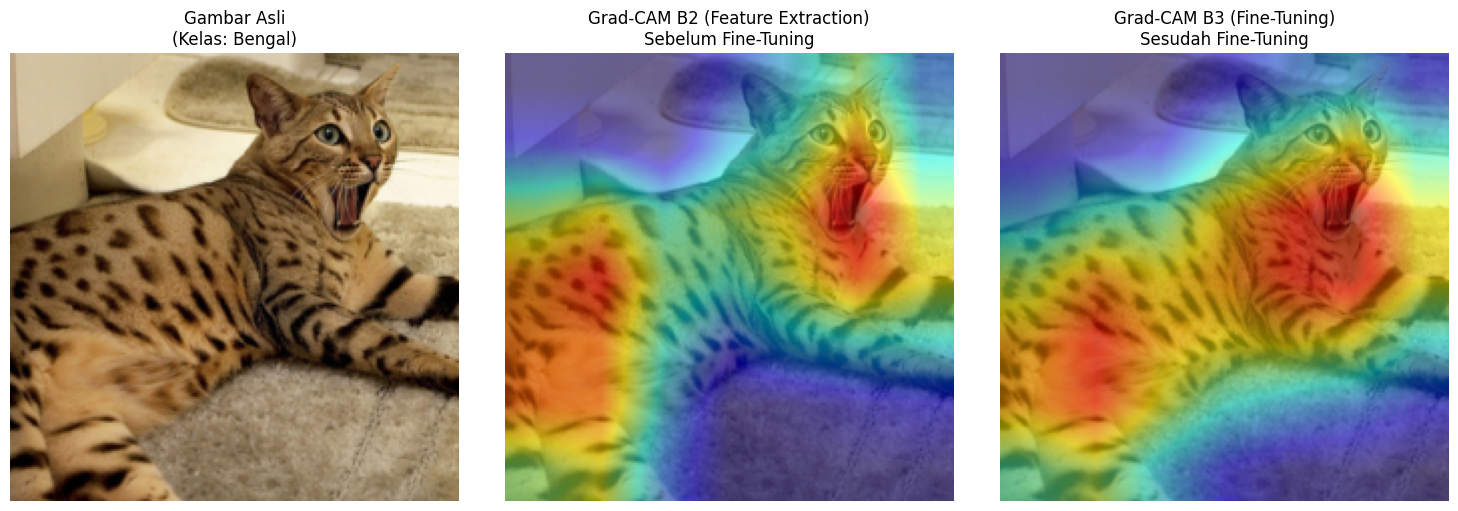

In [43]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# --- 1. Persiapan Gambar Uji ---
# Mengambil satu batch gambar dari test DataLoader
dataiter = iter(dataloaders['test'])
images, labels = next(dataiter)

# Pilih satu gambar (indeks 0)
img_tensor = images[0].unsqueeze(0).to(device)
true_label = labels[0].item()

# Denormalisasi gambar untuk visualisasi matplotlib (kembalikan ke RGB asli)
img_vis = images[0].numpy().transpose((1, 2, 0))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_vis = std * img_vis + mean
img_vis = np.clip(img_vis, 0, 1) # Format RGB float [0, 1]

# --- PERBAIKAN: Aktifkan gradien untuk kalkulasi Grad-CAM ---
# Grad-CAM mewajibkan adanya gradien. Kita buka sementara untuk model_b2.
for param in model_b2.layer4.parameters():
    param.requires_grad = True

for param in model_b3.layer4.parameters():
    param.requires_grad = True

# --- 2. Konfigurasi Grad-CAM ---
# Kita ekstrak aktivasi dari layer4 blok terakhir
target_layers_b2 = [model_b2.layer4[-1]]
target_layers_b3 = [model_b3.layer4[-1]]

# Inisialisasi objek GradCAM
cam_b2 = GradCAM(model=model_b2, target_layers=target_layers_b2)
cam_b3 = GradCAM(model=model_b3, target_layers=target_layers_b3)

# Targetkan kelas yang sebenarnya (ground truth)
targets = [ClassifierOutputTarget(true_label)]

# --- 3. Generate Heatmaps ---
# Menghasilkan grayscale CAM
grayscale_cam_b2 = cam_b2(input_tensor=img_tensor, targets=targets)[0, :]
grayscale_cam_b3 = cam_b3(input_tensor=img_tensor, targets=targets)[0, :]

# Menumpuk heatmap di atas gambar asli
visualization_b2 = show_cam_on_image(img_vis, grayscale_cam_b2, use_rgb=True)
visualization_b3 = show_cam_on_image(img_vis, grayscale_cam_b3, use_rgb=True)

# --- 4. Plotting Perbandingan ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_vis)
axes[0].set_title(f"Gambar Asli\n(Kelas: {selected_class_names[true_label]})", fontsize=12)
axes[0].axis('off')

axes[1].imshow(visualization_b2)
axes[1].set_title("Grad-CAM B2 (Feature Extraction)\nSebelum Fine-Tuning", fontsize=12)
axes[1].axis('off')

axes[2].imshow(visualization_b3)
axes[2].set_title("Grad-CAM B3 (Fine-Tuning)\nSesudah Fine-Tuning", fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.savefig('grad_cam_comparison.png', dpi=300)
plt.show()

In [44]:
import pandas as pd

# Membuat DataFrame dari dictionary results_log yang sudah ada
# (Pastikan Anda sudah menjalankan Sel 11 sebelumnya agar variabel results_log tersedia)
df_metrics = pd.DataFrame.from_dict(results_log, orient='index')

# Mengatur nama kolom index
df_metrics.index.name = 'Eksperimen'

# Menyimpan ke format CSV
df_metrics.to_csv('metrics_log.csv')

print("Berhasil menyimpan log evaluasi ke 'metrics_log.csv'")

Berhasil menyimpan log evaluasi ke 'metrics_log.csv'
